# 14 · Through-focus measurements and beam-size analysis: build it step by step

A through-focus experiment records images at known axial positions. We use a synthetic stack to explain calibration, normalization, and how to estimate a focus location without requiring connected lab hardware.

This companion develops the same idea with small functions defined beside the experiment that needs them.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


## 1. Generate profiles as a stand-in for measured frames

The synthetic stack isolates the analysis logic from instrument control. In a real experiment, the same array can be assembled from saved camera images and encoder positions.

In [ ]:
z_mm = np.linspace(-2, 2, 41)
x_um = np.linspace(-500, 500, 1001)
waist_um = 35
rayleigh_mm = 0.7
sigma_um = waist_um*np.sqrt(1+(z_mm/rayleigh_mm)**2)
profiles = np.array([np.exp(-x_um**2/(2*s**2)) for s in sigma_um]).T


## 2. Define profile width and locate its minimum

Use intensity weights to obtain one width per frame. The minimum is an operational focus estimate; aberrations and sampling can shift it from a geometric prediction.

In [ ]:
def profile_rms_width(intensity, x):
    """RMS width for an intensity profile and its coordinate axis."""
    weights = intensity/intensity.sum()
    center = np.sum(weights*x)
    return np.sqrt(np.sum(weights*(x-center)**2))

width_um = np.array([profile_rms_width(profile, x_um) for profile in profiles.T])


## 3. Attach physical positions to acquired profiles

A scan is only quantitative if each frame is associated with calibrated stage position. This helper converts encoder counts to a relative position axis.

In [ ]:
def counts_to_mm(counts, reference_counts, counts_per_mm):
    """Convert encoder counts to millimeters relative to a reference."""
    return (np.asarray(counts)-reference_counts)/counts_per_mm

counts_per_mm = 100_000
center_counts = 204_294
positions_counts = center_counts + np.linspace(-counts_per_mm, counts_per_mm, len(z_mm))
positions_mm = counts_to_mm(positions_counts, center_counts, counts_per_mm)
print("First and last positions (mm):", positions_mm[[0,-1]])


(-0.7, 0.7)

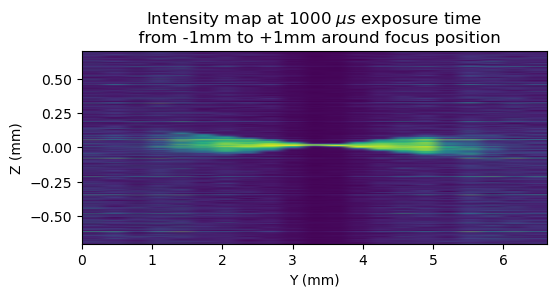

In [10]:
import matplotlib.pyplot as plt

I_z = np.zeros((length, 21))
plt.figure(figsize=(6, 2.5))
for i in range(21):
    position_mm = -2.0 + i * step_size_mm
    I_z[:,i] = np.load(os.path.join(save_dir, f"one_dim_sum_{i+1:03d}.npy"))
    I_z[:,i] /= np.max(I_z[:,i])  # normalize for better contrast

plt.imshow(I_z, extent=[0, length*pixel_size_um/1000, -2.0, 2.0], aspect='auto', origin='lower')
plt.xlabel('Y (mm)')
plt.ylabel('Z (mm)')
plt.title('Intensity map at 1000 $\mu s$ exposure time \n  from -1mm to +1mm around focus position', )
plt.ylim((-0.7,0.7))
#plt.title('Intensity map at x=3200 µm for z from -2mm to +2mm')